## Right hand

### Setup

(734, 81)
Samples: 734 total | 498 train | 89 val | 147 test
Class counts: {'Major': 159, 'Minor': 148, '7th': 148, 'sus4': 133, 'dim': 146}



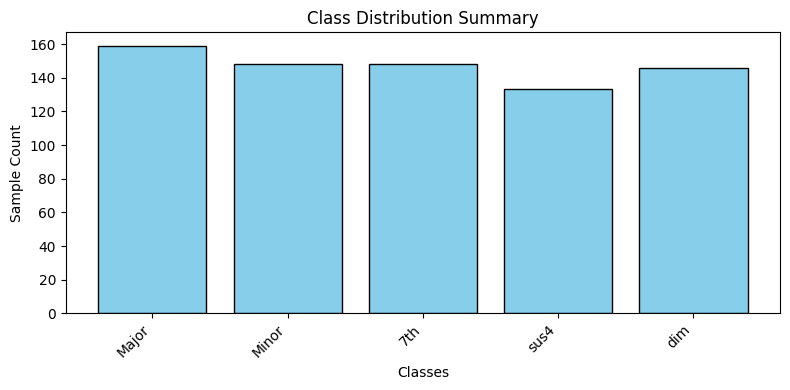

In [1]:
import utils

CSV_PATH = "data/right_hand_qualities.csv"
CLASSES_RIGHT = ["Major", "Minor", "7th", "sus4", "dim"]
PREFIX = "right"
EPOCHS = 50
TEACHER_HIDDEN = (128, 64)
CANDIDATES = [(48, 24), (32, 16), (28, 16), (24, 12), (16, 8), (12, 6), (8,), (4,)]

utils.seed_everything()
X, y = utils.load_csv(CSV_PATH, CLASSES_RIGHT)
print(X.shape)
splits = utils.make_splits(X, y)
utils.print_summary(y, splits, CLASSES_RIGHT)

### Visualization

In [2]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.preprocessing import StandardScaler

# X: raw features (n_samples, 81) = 27 points x (x, y, z); y: integer labels
X_pts = X.reshape(len(X), 27, 3)
X_std = StandardScaler().fit_transform(X).reshape(len(X), 27, 3)

bones = [(1,2),(2,3),(3,4),(4,5),(6,7),(7,8),(8,9),(9,10),(11,12),(6,1),(11,1),(16,1),(21,1),(7,12),(12,17),(17,22),
         (12,13),(13,14),(14,15),(16,17),(17,18),(18,19),(19,20),(21,22),(22,23),(23,24), (24,25)]

def hand_traces(pts, showlegend=False):
    """One hand as bone lines and joint markers (j0 to j24). palm_up is not plotted."""
    traces = []

    # Bones: one line trace, None values break the line between segments
    bx, by, bz = [], [], []
    for a, b in bones:
        if b < 26:
            bx += [pts[a, 0], pts[b, 0], None]
            by += [pts[a, 1], pts[b, 1], None]
            bz += [pts[a, 2], pts[b, 2], None]
    traces.append(go.Scatter3d(x=bx, y=by, z=bz, mode="lines",
                               line=dict(width=4), name="bones", showlegend=showlegend,
                               hoverinfo="skip"))

    # Landmarks j0..j25 with hover info
    traces.append(go.Scatter3d(
        x=pts[:26, 0], y=pts[:26, 1], z=pts[:26, 2], mode="markers",
        marker=dict(size=5),
        text=[f"j{k}" for k in range(26)],
        hovertemplate="%{text}<br>x=%{x:.3f}<br>y=%{y:.3f}<br>z=%{z:.3f}<extra></extra>",
        name="landmarks", showlegend=showlegend))
    return traces


# 1) One sample, raw vs standardized, side by side
i = 0  # change to inspect another sample
fig = make_subplots(rows=1, cols=2,
                    specs=[[{"type": "scene"}, {"type": "scene"}]],
                    subplot_titles=["Raw", "Standardized"])
i = 0
for t in hand_traces(X_pts[i]):
    fig.add_trace(t, row=1, col=1)
for t in hand_traces(X_std[i]):
    fig.add_trace(t, row=1, col=2)
fig.update_layout(title=f"Sample {i} (label {CLASSES_RIGHT[y[i]]})", height=600)
fig.show()


# 2) All samples' landmarks, raw vs standardized, colored by class
X_std_joints = X_std[:, :26]
X_raw_joints = X_pts[:, :26]

pts_class = np.repeat(y, 26)
labels_hover = np.repeat([CLASSES_RIGHT[k] for k in y], 26)

fig2 = make_subplots(rows=1, cols=2,
                     specs=[[{"type": "scene"}, {"type": "scene"}]],
                     subplot_titles=["Raw", "Standardized"])
for col, arr in [(1, X_raw_joints), (2, X_std_joints)]:
    j = arr.reshape(-1, 3)
    fig2.add_trace(go.Scatter3d(
        x=j[:, 0], y=j[:, 1], z=j[:, 2], mode="markers",
        marker=dict(size=2, color=pts_class, colorscale="Turbo", opacity=0.6),
        text=labels_hover,
        hovertemplate="%{text}<br>x=%{x:.3f}<br>y=%{y:.3f}<br>z=%{z:.3f}<extra></extra>",
        showlegend=False), row=1, col=col)
fig2.update_layout(title="Joints, all samples (color = class)", height=600)
fig2.show()

GIF generation is pretty slow, it can be skipped

In [3]:
'''
import io

import numpy as np
from PIL import Image


def rotating_gif(fig, scene_ids=("scene", "scene2"), n_frames=60,
                 radius=2.6, elevation=0.6, width=1000, height=600):
    """Orbit the camera around every 3D scene in `fig` and save the result as a GIF."""
    fig.update_layout(width=width, height=height)
    frames = []
    for k in range(n_frames):
        print(f"Frame {k + 1}/{n_frames}")
        theta = 2 * np.pi * k / n_frames
        eye = dict(x=radius * np.cos(theta), y=radius * np.sin(theta), z=elevation)
        fig.update_layout(**{f"{s}_camera": dict(eye=eye) for s in scene_ids})
        png = fig.to_image(format="png")  # requires kaleido
        frames.append(Image.open(io.BytesIO(png)).convert("RGB"))

    return frames
    

path = "resources/right_hand_before_after.gif"
# 1) Single sample, raw vs standardized
frames = rotating_gif(fig, scene_ids=("scene", "scene2"))
'''

'\nimport io\n\nimport numpy as np\nfrom PIL import Image\n\n\ndef rotating_gif(fig, scene_ids=("scene", "scene2"), n_frames=60,\n                 radius=2.6, elevation=0.6, width=1000, height=600):\n    """Orbit the camera around every 3D scene in `fig` and save the result as a GIF."""\n    fig.update_layout(width=width, height=height)\n    frames = []\n    for k in range(n_frames):\n        print(f"Frame {k + 1}/{n_frames}")\n        theta = 2 * np.pi * k / n_frames\n        eye = dict(x=radius * np.cos(theta), y=radius * np.sin(theta), z=elevation)\n        fig.update_layout(**{f"{s}_camera": dict(eye=eye) for s in scene_ids})\n        png = fig.to_image(format="png")  # requires kaleido\n        frames.append(Image.open(io.BytesIO(png)).convert("RGB"))\n\n    return frames\n    \n\npath = "resources/right_hand_before_after.gif"\n# 1) Single sample, raw vs standardized\nframes = rotating_gif(fig, scene_ids=("scene", "scene2"))\n'

In [4]:

'''
frames[0].save(path, save_all=True, append_images=frames[1:],
                   duration=60, loop=0)
print(f"Saved {path}")
'''

'\nframes[0].save(path, save_all=True, append_images=frames[1:],\n                   duration=60, loop=0)\nprint(f"Saved {path}")\n'

In [5]:
'''
# 2) All samples, raw vs standardized
path_all = "resources/right_hand_all_before_after.gif"
frames_all = rotating_gif(fig2, scene_ids=("scene", "scene2"),
             n_frames=60)
'''

'\n# 2) All samples, raw vs standardized\npath_all = "resources/right_hand_all_before_after.gif"\nframes_all = rotating_gif(fig2, scene_ids=("scene", "scene2"),\n             n_frames=60)\n'

In [6]:

'''
frames_all[0].save(path_all, save_all=True, append_images=frames_all[1:],
                   duration=60, loop=0)
print(f"Saved {path_all}")
'''

'\nframes_all[0].save(path_all, save_all=True, append_images=frames_all[1:],\n                   duration=60, loop=0)\nprint(f"Saved {path_all}")\n'

### Support Vector Machine

In [ ]:
svm = utils.train_svm(splits)
utils.report_predictions("SVM (test)", splits["y_test"], svm.predict(splits["X_test"]), CLASSES_RIGHT)

s = utils.svm_size(svm)
print(f"Support vectors: {s['n_sv']} of {len(splits['y_train'])} | "
      f"stored numbers: {s['n_numbers']:,}")
print(f"ONNX: {utils.export_svm_onnx(svm, splits['X_train'], f'model/{PREFIX}_svm.onnx'):.2f} KB")

SVM (test) accuracy: 100.00%
              precision    recall  f1-score   support

       Major       1.00      1.00      1.00        32
       Minor       1.00      1.00      1.00        30
         7th       1.00      1.00      1.00        30
        sus4       1.00      1.00      1.00        26
         dim       1.00      1.00      1.00        29

    accuracy                           1.00       147
   macro avg       1.00      1.00      1.00       147
weighted avg       1.00      1.00      1.00       147

Confusion matrix (rows = true, cols = predicted):
[[32  0  0  0  0]
 [ 0 30  0  0  0]
 [ 0  0 30  0  0]
 [ 0  0  0 26  0]
 [ 0  0  0  0 29]] 

Support vectors: 54 of 498 | stored numbers: 4,600
ONNX: 24.47 KB


### Multi-Layer Perceptron

In [ ]:
utils.seed_everything()
train_loader = utils.to_loader(splits["X_train"], splits["y_train"], shuffle=True)
teacher = utils.make_mlp(TEACHER_HIDDEN, len(CLASSES_RIGHT), splits)
utils.train_mlp(teacher, train_loader, splits, epochs=EPOCHS)

utils.report_predictions("MLP teacher (test)", splits["y_test"],
                      utils.torch_predict(teacher, splits["X_test"]), CLASSES_RIGHT)
print(f"Parameters: {utils.count_params(teacher):,}")
print(f"ONNX: {utils.export_torch_onnx(teacher, f'model/{PREFIX}_teacher.onnx'):.2f} KB")

epoch  10 | val acc 100.00%
epoch  20 | val acc 100.00%
epoch  30 | val acc 100.00%
epoch  40 | val acc 100.00%
epoch  50 | val acc 100.00%
MLP teacher (test) accuracy: 100.00%
              precision    recall  f1-score   support

       Major       1.00      1.00      1.00        32
       Minor       1.00      1.00      1.00        30
         7th       1.00      1.00      1.00        30
        sus4       1.00      1.00      1.00        26
         dim       1.00      1.00      1.00        29

    accuracy                           1.00       147
   macro avg       1.00      1.00      1.00       147
weighted avg       1.00      1.00      1.00       147

Confusion matrix (rows = true, cols = predicted):
[[32  0  0  0  0]
 [ 0 30  0  0  0]
 [ 0  0 30  0  0]
 [ 0  0  0 26  0]
 [ 0  0  0  0 29]] 

Parameters: 19,077
ONNX: 77.77 KB


### Model distillation

In [ ]:
best = utils.sweep_distillation(teacher, splits, CANDIDATES, len(CLASSES_RIGHT), epochs=EPOCHS)

if best is None:
    print("\nNo candidate met the threshold. Try larger candidates or more epochs.")
else:
    student = best["model"]
    print(f"\nSmallest accepted: {best['hidden']}, {best['params']:,} params")
    utils.report_predictions("Student (test)", splits["y_test"],
                          utils.torch_predict(student, splits["X_test"]), CLASSES_RIGHT)
    print(f"ONNX: {utils.export_torch_onnx(student, f'model/{PREFIX}_student.onnx'):.2f} KB")

Teacher: 19,077 params, val acc 100.00%
Threshold: 98.00%

      Hidden |  Params |  Val Acc | OK
------------------------------------------
    (48, 24) |   5,237 | 100.00% | yes
    (32, 16) |   3,237 | 100.00% | yes
    (28, 16) |   2,845 | 100.00% | yes
    (24, 12) |   2,333 | 100.00% | yes
     (16, 8) |   1,493 | 100.00% | yes
     (12, 6) |   1,097 | 100.00% | yes
        (8,) |     701 | 100.00% | yes
        (4,) |     353 |  61.80% | no

Smallest accepted: (8,), 701 params
Student (test) accuracy: 100.00%
              precision    recall  f1-score   support

       Major       1.00      1.00      1.00        32
       Minor       1.00      1.00      1.00        30
         7th       1.00      1.00      1.00        30
        sus4       1.00      1.00      1.00        26
         dim       1.00      1.00      1.00        29

    accuracy                           1.00       147
   macro avg       1.00      1.00      1.00       147
weighted avg       1.00      1.00      1.00 

### Confidence analysis

In [ ]:
probs_svm = svm.predict_proba(splits["X_test"])
probs_teacher = utils.get_probs_torch(teacher, splits["X_test"])
probs_student = utils.get_probs_torch(student, splits["X_test"])

utils.confidence_report("SVM", probs_svm, splits["y_test"], CLASSES_RIGHT)
utils.confidence_report("MLP teacher", probs_teacher, splits["y_test"], CLASSES_RIGHT)
utils.confidence_report("Distilled student", probs_student, splits["y_test"], CLASSES_RIGHT)

== SVM ==
 Class |    N |     Acc | Mean conf | Min conf (ok) | Conf (wrong) | P(true)
--------------------------------------------------------------------------
 Major |   32 | 100.00% |   97.00% |       95.93% |        nan% |  0.970
 Minor |   30 | 100.00% |   97.13% |       95.48% |        nan% |  0.971
   7th |   30 | 100.00% |   96.46% |       94.69% |        nan% |  0.965
  sus4 |   26 | 100.00% |   95.86% |       94.97% |        nan% |  0.959
   dim |   29 | 100.00% |   97.29% |       95.90% |        nan% |  0.973

Overall: accuracy 100.00%, mean conf 96.77%, ECE 0.0323
Low-confidence or wrong samples: 0

== MLP teacher ==
 Class |    N |     Acc | Mean conf | Min conf (ok) | Conf (wrong) | P(true)
--------------------------------------------------------------------------
 Major |   32 | 100.00% |  100.00% |       99.99% |        nan% |  1.000
 Minor |   30 | 100.00% |   99.99% |       99.97% |        nan% |  1.000
   7th |   30 | 100.00% |  100.00% |       99.93% |        nan% 

## Left hand

### Setup

Samples: 1031 total | 700 train | 124 val | 207 test
Class counts: {'A': 125, 'B': 93, 'C': 152, 'D': 148, 'E': 148, 'F': 185, 'G': 180}



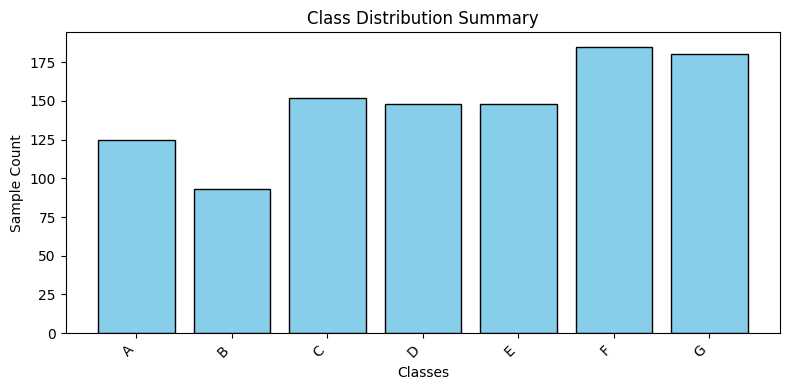

In [ ]:
import utils

CSV_PATH = "data/left_hand_notes.csv"
CLASSES_LEFT = ["A", "B", "C", "D", "E", "F", "G"]
PREFIX = "left"
EPOCHS = 50
TEACHER_HIDDEN = (128, 64)
CANDIDATES = [(48, 24), (32, 16), (28, 16), (24, 12), (16, 8), (12, 6), (8,)]

utils.seed_everything()
X, y = utils.load_csv(CSV_PATH, classes=CLASSES_LEFT)
splits = utils.make_splits(X, y)
utils.print_summary(y, splits, CLASSES_LEFT)

### Visualization

In [ ]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.preprocessing import StandardScaler

# X: raw features (n_samples, 81) = 27 points x (x, y, z); y: integer labels
X_pts = X.reshape(len(X), 27, 3)
X_std = StandardScaler().fit_transform(X).reshape(len(X), 27, 3)

bones = [(1,2),(2,3),(3,4),(4,5),(6,7),(7,8),(8,9),(9,10),(11,12),(6,1),(11,1),(16,1),(21,1),(7,12),(12,17),(17,22),
         (12,13),(13,14),(14,15),(16,17),(17,18),(18,19),(19,20),(21,22),(22,23),(23,24), (24,25)]

def hand_traces(pts, showlegend=False):
    """One hand as bone lines and joint markers (j0 to j24). palm_up is not plotted."""
    traces = []

    # Bones: one line trace, None values break the line between segments
    bx, by, bz = [], [], []
    for a, b in bones:
        if b < 26:
            bx += [pts[a, 0], pts[b, 0], None]
            by += [pts[a, 1], pts[b, 1], None]
            bz += [pts[a, 2], pts[b, 2], None]
    traces.append(go.Scatter3d(x=bx, y=by, z=bz, mode="lines",
                               line=dict(width=4), name="bones", showlegend=showlegend,
                               hoverinfo="skip"))

    # Landmarks j0..j25 with hover info
    traces.append(go.Scatter3d(
        x=pts[:26, 0], y=pts[:26, 1], z=pts[:26, 2], mode="markers",
        marker=dict(size=5),
        text=[f"j{k}" for k in range(26)],
        hovertemplate="%{text}<br>x=%{x:.3f}<br>y=%{y:.3f}<br>z=%{z:.3f}<extra></extra>",
        name="landmarks", showlegend=showlegend))
    return traces


# 1) One sample, raw vs standardized, side by side
i = 1030  # change to inspect another sample
fig = make_subplots(rows=1, cols=2,
                    specs=[[{"type": "scene"}, {"type": "scene"}]],
                    subplot_titles=["Raw", "Standardized"])
for t in hand_traces(X_pts[i]):
    fig.add_trace(t, row=1, col=1)
for t in hand_traces(X_std[i]):
    fig.add_trace(t, row=1, col=2)
fig.update_layout(title=f"Sample {i} (label {CLASSES_LEFT[y[i]]})", height=600)
fig.show()


# 2) All samples' landmarks, raw vs standardized, colored by class
X_std_joints = X_std[:, :25]
X_raw_joints = X_pts[:, :25]

pts_class = np.repeat(y, 25)
labels_hover = np.repeat([CLASSES_LEFT[k] for k in y], 25)

fig2 = make_subplots(rows=1, cols=2,
                     specs=[[{"type": "scene"}, {"type": "scene"}]],
                     subplot_titles=["Raw", "Standardized"])
for col, arr in [(1, X_raw_joints), (2, X_std_joints)]:
    j = arr.reshape(-1, 3)
    fig2.add_trace(go.Scatter3d(
        x=j[:, 0], y=j[:, 1], z=j[:, 2], mode="markers",
        marker=dict(size=2, color=pts_class, colorscale="Turbo", opacity=0.6),
        text=labels_hover,
        hovertemplate="%{text}<br>x=%{x:.3f}<br>y=%{y:.3f}<br>z=%{z:.3f}<extra></extra>",
        showlegend=False), row=1, col=col)
fig2.update_layout(title="Joints, all samples (color = class)", height=600)
fig2.show()

GIF generation is pretty slow, so it can be skipped

In [ ]:
'''
import io

import numpy as np
from PIL import Image


def rotating_gif(fig, scene_ids=("scene", "scene2"), n_frames=60,
                 radius=2.6, elevation=0.6, width=1000, height=600):
    """Orbit the camera around every 3D scene in `fig` and save the result as a GIF."""
    fig.update_layout(width=width, height=height)
    frames = []
    for k in range(n_frames):
        print(f"Frame {k + 1}/{n_frames}")
        theta = 2 * np.pi * k / n_frames
        eye = dict(x=radius * np.cos(theta), y=radius * np.sin(theta), z=elevation)
        fig.update_layout(**{f"{s}_camera": dict(eye=eye) for s in scene_ids})
        png = fig.to_image(format="png")  # requires kaleido
        frames.append(Image.open(io.BytesIO(png)).convert("RGB"))

    return frames
    

path = "resources/left_hand_before_after.gif"
# 1) Single sample, raw vs standardized
frames = rotating_gif(fig, scene_ids=("scene", "scene2"))
'''

Frame 1/60
Frame 2/60
Frame 3/60
Frame 4/60
Frame 5/60
Frame 6/60
Frame 7/60
Frame 8/60
Frame 9/60
Frame 10/60
Frame 11/60
Frame 12/60
Frame 13/60
Frame 14/60
Frame 15/60
Frame 16/60
Frame 17/60
Frame 18/60
Frame 19/60
Frame 20/60
Frame 21/60
Frame 22/60
Frame 23/60
Frame 24/60
Frame 25/60
Frame 26/60
Frame 27/60
Frame 28/60
Frame 29/60
Frame 30/60
Frame 31/60
Frame 32/60
Frame 33/60
Frame 34/60
Frame 35/60
Frame 36/60
Frame 37/60
Frame 38/60
Frame 39/60
Frame 40/60
Frame 41/60
Frame 42/60
Frame 43/60
Frame 44/60
Frame 45/60
Frame 46/60
Frame 47/60
Frame 48/60
Frame 49/60
Frame 50/60
Frame 51/60
Frame 52/60
Frame 53/60
Frame 54/60
Frame 55/60
Frame 56/60
Frame 57/60
Frame 58/60
Frame 59/60
Frame 60/60


In [ ]:
'''
frames[0].save(path, save_all=True, append_images=frames[1:],
                   duration=60, loop=0)
print(f"Saved {path}")
'''

Saved left_hand_before_after.gif


In [ ]:
'''
# 2) All samples, raw vs standardized
path_all = "resources/left_hand_all_before_after.gif"
frames_all = rotating_gif(fig2, scene_ids=("scene", "scene2"),
             n_frames=60)
'''

Frame 1/60
Frame 2/60
Frame 3/60
Frame 4/60
Frame 5/60
Frame 6/60
Frame 7/60
Frame 8/60
Frame 9/60
Frame 10/60
Frame 11/60
Frame 12/60
Frame 13/60
Frame 14/60
Frame 15/60
Frame 16/60
Frame 17/60
Frame 18/60
Frame 19/60
Frame 20/60
Frame 21/60
Frame 22/60
Frame 23/60
Frame 24/60
Frame 25/60
Frame 26/60
Frame 27/60
Frame 28/60
Frame 29/60
Frame 30/60
Frame 31/60
Frame 32/60
Frame 33/60
Frame 34/60
Frame 35/60
Frame 36/60
Frame 37/60
Frame 38/60
Frame 39/60
Frame 40/60
Frame 41/60
Frame 42/60
Frame 43/60
Frame 44/60
Frame 45/60
Frame 46/60
Frame 47/60
Frame 48/60
Frame 49/60
Frame 50/60
Frame 51/60
Frame 52/60
Frame 53/60
Frame 54/60
Frame 55/60
Frame 56/60
Frame 57/60
Frame 58/60
Frame 59/60
Frame 60/60


In [ ]:
'''
frames_all[0].save(path_all, save_all=True, append_images=frames_all[1:],
                   duration=60, loop=0)
print(f"Saved {path_all}")
'''

Saved left_hand_all_before_after.gif


### Support Vector Machine

In [ ]:
svm = utils.train_svm(splits)
utils.report_predictions("SVM (test)", splits["y_test"], svm.predict(splits["X_test"]), CLASSES_LEFT)

s = utils.svm_size(svm)
print(f"Support vectors: {s['n_sv']} of {len(splits['y_train'])} | "
      f"stored numbers: {s['n_numbers']:,}")
print(f"ONNX: {utils.export_svm_onnx(svm, splits['X_train'], f'model/{PREFIX}_svm.onnx'):.2f} KB")

SVM (test) accuracy: 100.00%
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        25
           B       1.00      1.00      1.00        19
           C       1.00      1.00      1.00        30
           D       1.00      1.00      1.00        30
           E       1.00      1.00      1.00        30
           F       1.00      1.00      1.00        37
           G       1.00      1.00      1.00        36

    accuracy                           1.00       207
   macro avg       1.00      1.00      1.00       207
weighted avg       1.00      1.00      1.00       207

Confusion matrix (rows = true, cols = predicted):
[[25  0  0  0  0  0  0]
 [ 0 19  0  0  0  0  0]
 [ 0  0 30  0  0  0  0]
 [ 0  0  0 30  0  0  0]
 [ 0  0  0  0 30  0  0]
 [ 0  0  0  0  0 37  0]
 [ 0  0  0  0  0  0 36]] 

Support vectors: 94 of 700 | stored numbers: 8,199
ONNX: 42.58 KB


### Multi-Layer Perceptron

In [ ]:
utils.seed_everything()
train_loader = utils.to_loader(splits["X_train"], splits["y_train"], shuffle=True)
teacher = utils.make_mlp(TEACHER_HIDDEN, len(CLASSES_LEFT), splits)
utils.train_mlp(teacher, train_loader, splits, epochs=EPOCHS)

utils.report_predictions("MLP teacher (test)", splits["y_test"],
                      utils.torch_predict(teacher, splits["X_test"]), CLASSES_LEFT)
print(f"Parameters: {utils.count_params(teacher):,}")
print(f"ONNX: {utils.export_torch_onnx(teacher, f'model/{PREFIX}_teacher.onnx'):.2f} KB")

epoch  10 | val acc 100.00%
epoch  20 | val acc 100.00%
epoch  30 | val acc 100.00%
epoch  40 | val acc 100.00%
epoch  50 | val acc 100.00%
MLP teacher (test) accuracy: 100.00%
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        25
           B       1.00      1.00      1.00        19
           C       1.00      1.00      1.00        30
           D       1.00      1.00      1.00        30
           E       1.00      1.00      1.00        30
           F       1.00      1.00      1.00        37
           G       1.00      1.00      1.00        36

    accuracy                           1.00       207
   macro avg       1.00      1.00      1.00       207
weighted avg       1.00      1.00      1.00       207

Confusion matrix (rows = true, cols = predicted):
[[25  0  0  0  0  0  0]
 [ 0 19  0  0  0  0  0]
 [ 0  0 30  0  0  0  0]
 [ 0  0  0 30  0  0  0]
 [ 0  0  0  0 30  0  0]
 [ 0  0  0  0  0 37  0]
 [ 0  0  0  0  0  0 36]] 

Param

### Model distillation

In [ ]:
best = utils.sweep_distillation(teacher, splits, CANDIDATES, len(CLASSES_LEFT), epochs=EPOCHS)

if best is None:
    print("\nNo candidate met the threshold. Try larger candidates or more epochs.")
else:
    student = best["model"]
    print(f"\nSmallest accepted: {best['hidden']}, {best['params']:,} params")
    utils.report_predictions("Student (test)", splits["y_test"],
                          utils.torch_predict(student, splits["X_test"]), CLASSES_LEFT)
    print(f"ONNX: {utils.export_torch_onnx(student, f'model/{PREFIX}_student.onnx'):.2f} KB")

Teacher: 19,207 params, val acc 100.00%
Threshold: 98.00%

      Hidden |  Params |  Val Acc | OK
------------------------------------------
    (48, 24) |   5,287 | 100.00% | yes
    (32, 16) |   3,271 | 100.00% | yes
    (28, 16) |   2,879 | 100.00% | yes
    (24, 12) |   2,359 | 100.00% | yes
     (16, 8) |   1,511 | 100.00% | yes
     (12, 6) |   1,111 | 100.00% | yes
        (8,) |     719 | 100.00% | yes

Smallest accepted: (8,), 719 params
Student (test) accuracy: 100.00%
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        25
           B       1.00      1.00      1.00        19
           C       1.00      1.00      1.00        30
           D       1.00      1.00      1.00        30
           E       1.00      1.00      1.00        30
           F       1.00      1.00      1.00        37
           G       1.00      1.00      1.00        36

    accuracy                           1.00       207
   macro avg       1.00     

### Confidence analysis

In [ ]:
probs_svm = svm.predict_proba(splits["X_test"])
probs_teacher = utils.get_probs_torch(teacher, splits["X_test"])
probs_student = utils.get_probs_torch(student, splits["X_test"])

utils.confidence_report("SVM", probs_svm, splits["y_test"], CLASSES_LEFT)
utils.confidence_report("MLP teacher", probs_teacher, splits["y_test"], CLASSES_LEFT)
utils.confidence_report("Distilled student", probs_student, splits["y_test"], CLASSES_LEFT)

== SVM ==
 Class |    N |     Acc | Mean conf | Min conf (ok) | Conf (wrong) | P(true)
--------------------------------------------------------------------------
     A |   25 | 100.00% |   95.17% |       93.24% |        nan% |  0.952
     B |   19 | 100.00% |   93.75% |       89.89% |        nan% |  0.937
     C |   30 | 100.00% |   95.85% |       85.88% |        nan% |  0.959
     D |   30 | 100.00% |   95.72% |       92.69% |        nan% |  0.957
     E |   30 | 100.00% |   95.38% |       93.59% |        nan% |  0.954
     F |   37 | 100.00% |   96.69% |       93.27% |        nan% |  0.967
     G |   36 | 100.00% |   96.45% |       94.63% |        nan% |  0.965

Overall: accuracy 100.00%, mean conf 95.74%, ECE 0.0426
Low-confidence or wrong samples: 0

== MLP teacher ==
 Class |    N |     Acc | Mean conf | Min conf (ok) | Conf (wrong) | P(true)
--------------------------------------------------------------------------
     A |   25 | 100.00% |   99.99% |       99.92% |        nan% 

### Inference example

In [ ]:
import numpy as np
import onnxruntime as ort

# 1. Load the model
session = ort.InferenceSession("model/left_student.onnx", providers=["CPUExecutionProvider"])

# 2. Inspect the expected inputs (names, shapes, dtypes)
for inp in session.get_inputs():
    print("input:", inp.name, inp.shape, inp.type)
for out in session.get_outputs():
    print("output:", out.name, out.shape, out.type)

# 3. Build a sample matching the input spec
input_name = session.get_inputs()[0].name
x_row = np.asarray(X[1030], dtype=np.float32).reshape(1, -1)

# 4. Run inference (None = return all outputs)
outputs = session.run(None, {input_name: x_row})
print("prediction:", outputs[0])
print("true label:", y[1030])

logits = outputs[0][0]                        # shape (7,)
exp = np.exp(logits - logits.max())           # subtract max for numerical stability
probs = exp / exp.sum()

pred_idx = int(np.argmax(probs))
confidence = float(probs[pred_idx])

print("predicted index:", pred_idx)
print("predicted class:", CLASSES_LEFT[pred_idx])  # assumes the list order matches training
print("confidence:", confidence)



input: input ['batch', 81] tensor(float)
output: output ['batch', 7] tensor(float)
prediction: [[-16.184542   -10.59455     -3.4942489    0.09499456  -1.6561387
   -4.6138573   10.778313  ]]
true label: 6
predicted index: 6
predicted class: G
confidence: 0.9999722242355347
